In [1]:
# Assignment No: 02
# Aim: To Implement Feedforward neural networks with Keras and TensorFlow
# Objectives:
# 1. Apply feedforward neural network on MNIST dataset for classification.
# 2. Evaluate the performance of models and plot the loss and accuracy graph.

In [1]:
# a. Import the necessary packages

# If needed, uncomment:
# %pip install -q tensorflow matplotlib

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import SGD

In [3]:
# b. Load the training and testing data (MNIST)
# Load the MNIST dataset
mnist = tf.keras.datasets.mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalize the pixel values to be between 0 and 1
X_train = X_train / 255.0
X_test = X_test / 255.0

print(f"Training data shape: {X_train.shape}")
print(f"Testing data shape: {X_test.shape}")

Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


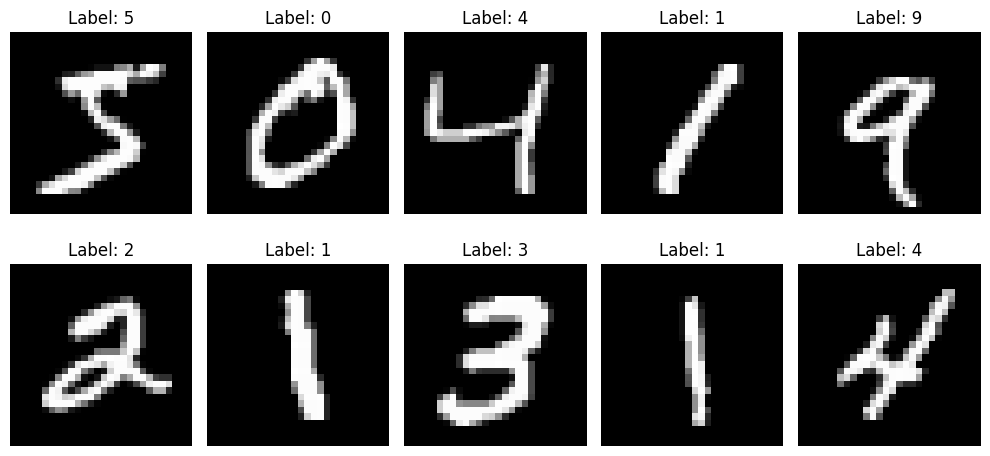

In [5]:
# Preview the training dataset
# Plot the first 10 digits from the training set to preview the data
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [7]:
# c. Define the network architecture using Keras
# Define the Feedforward Neural Network
model = Sequential([
    Flatten(input_shape=(28, 28)),          # Flatten the 2D images to 1D vectors
    Dense(128, activation='relu'),          # Hidden layer with ReLU activation
    Dense(64, activation='relu'),           # Optional second hidden layer
    Dense(10, activation='softmax')         # Output layer with Softmax for classification
])

model.summary()

C:\Users\prati\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# d. Train the model using SGD
# Compile the model using SGD optimizer and cross-entropy loss
sgd_optimizer = SGD(learning_rate=0.01)
model.compile(
    optimizer=sgd_optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
EPOCHS = 20
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=EPOCHS,
    batch_size=64
)

Epoch 1/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.7704 - loss: 0.8900 - val_accuracy: 0.8887 - val_loss: 0.4135
Epoch 2/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.8978 - loss: 0.3705 - val_accuracy: 0.9090 - val_loss: 0.3184
Epoch 3/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.9130 - loss: 0.3062 - val_accuracy: 0.9228 - val_loss: 0.2746
Epoch 4/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9236 - loss: 0.2710 - val_accuracy: 0.9295 - val_loss: 0.2510
Epoch 5/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9305 - loss: 0.2455 - val_accuracy: 0.9345 - val_loss: 0.2298
Epoch 6/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9369 - loss: 0.2250 - val_accuracy: 0.9376 - val_loss: 0.2140
Epoch 7/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9412 - loss: 0.2074 - val_accuracy: 0.9437 - val_loss: 0.1959
Epoch 8/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9455 - loss: 0.1924 - val_accura

In [11]:
# e. Evaluate the network
# Evaluate the model on test data
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

Test Accuracy: 0.9669
Test Loss: 0.1165


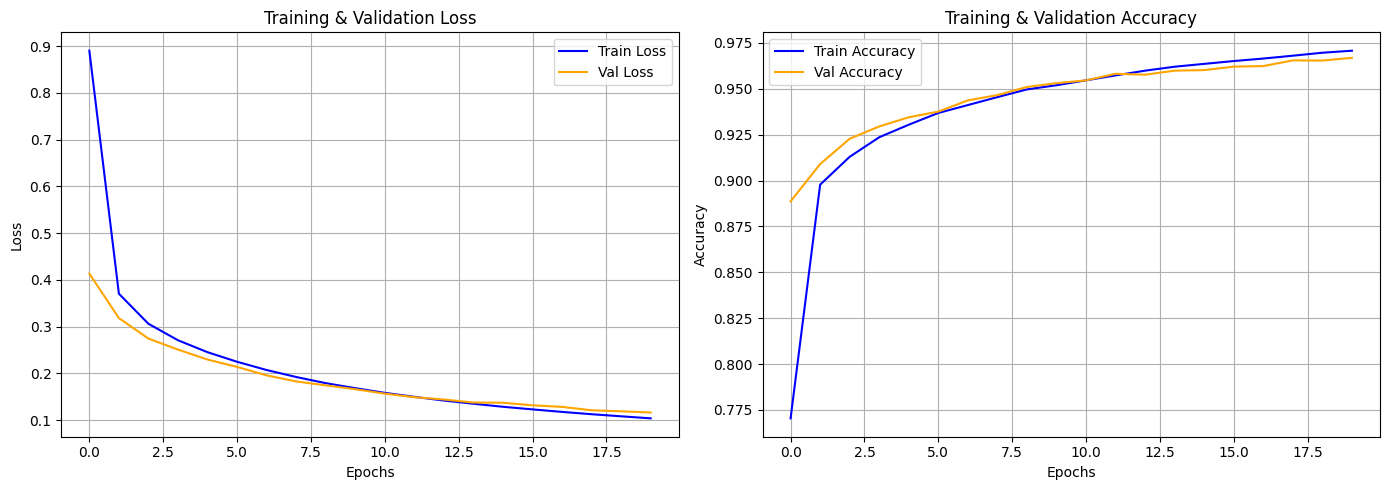

In [13]:
# f. Plot the training loss and accuracy
# Create subplots for loss and accuracy curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot Loss
ax1.plot(history.history['loss'], label='Train Loss', color='blue')
ax1.plot(history.history['val_loss'], label='Val Loss', color='orange')
ax1.set_title('Training & Validation Loss')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

# Plot Accuracy
ax2.plot(history.history['accuracy'], label='Train Accuracy', color='blue')
ax2.plot(history.history['val_accuracy'], label='Val Accuracy', color='orange')
ax2.set_title('Training & Validation Accuracy')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()